
# Adaptive Clinical Residual Modulation for Multimodal Skin Lesion Classification

**Dataset:** PAD-UFES-20  
**Research project:** Computer Vision and Multimodal Machine Learning  
**Experimental framework:** Five-fold patient-grouped cross-validation  
**Primary evaluation metric:** Macro-averaged F1-score

## Research Objective

This notebook documents the experimental evaluation of **Adaptive Clinical Residual Modulation (ACRM)**, a multimodal classification architecture designed to integrate clinical metadata with visual representations for skin lesion diagnosis.

The study investigates whether metadata-conditioned residual modulation and adaptive gating improve classification performance over image-only prediction and alternative multimodal fusion strategies.

## Experimental Design

All architectures are evaluated using the same predefined five patient-grouped cross-validation folds to support consistent, patient-independent comparisons.

The experimental evaluation includes:

1. **Image-only baseline:** EfficientNet-B0 using clinical images without metadata.
2. **Concatenation baseline:** Fusion of visual and encoded clinical features.
3. **MetaBlock-SE:** Metadata-conditioned channel-wise feature modulation.
4. **MMF-Net:** Attention-based multimodal feature fusion.
5. **Full ACRM:** Proposed metadata-conditioned residual modulation with adaptive gating.
6. **ACRM without gating:** Ablation evaluating the contribution of the adaptive gate.
7. **ACRM without residual modulation and gating:** Ablation evaluating the combined contribution of these mechanisms.

## Evaluation Protocol

Model performance is assessed using macro-F1, balanced accuracy, macro-AUROC, confusion matrices, and per-class recall.

The analysis additionally includes paired fold-level statistical comparisons, parameter counts, inference latency, GPU memory consumption, and an accuracy–efficiency assessment.

## Reproducibility and Implementation

The notebook uses the project's version-controlled Python implementation, with shared preprocessing, training, and evaluation procedures.

Previously completed experimental results are retained in the repository. Training sections document how the experiments were executed, while subsequent sections analyse the saved outputs without requiring model retraining.

The notebook distinguishes the pretrained EfficientNet-B0 backbone from the custom multimodal fusion components and experimental evaluation pipeline.



## 1. Environment and Project Setup

The experimental implementation is maintained in a version-controlled GitHub repository. This section retrieves the project source code into the Google Colab runtime and records the checked-out commit for traceability.

Repository access uses a GitHub token stored in Colab Secrets. Credentials are not embedded in the notebook or repository.

Subsequent sections use the same project implementation for dataset preparation, model execution, evaluation, and result analysis.


In [1]:
from google.colab import userdata
import os
import subprocess
from pathlib import Path

REPO_DIR = Path("/content/PAD_UFES_Capstone")
REPO_URL = "https://github.com/SaharHassanAAlzahrani/PAD_UFES_Capstone.git"

if not REPO_DIR.exists():
    token = userdata.get("GITHUB_TOKEN")

    env = os.environ.copy()
    env["GITHUB_TOKEN"] = token
    env["GIT_TERMINAL_PROMPT"] = "0"

    askpass = Path("/tmp/github_askpass.sh")
    askpass.write_text(
        '#!/bin/sh\n'
        'case "$1" in\n'
        '  *Username*) echo "oauth2" ;;\n'
        '  *Password*) echo "$GITHUB_TOKEN" ;;\n'
        'esac\n'
    )
    askpass.chmod(0o700)
    env["GIT_ASKPASS"] = str(askpass)

    subprocess.run(
        ["git", "clone", REPO_URL, str(REPO_DIR)],
        check=True,
        env=env,
    )

os.chdir(REPO_DIR)

print(f"Repository: {REPO_DIR}")
print(
    "Commit:",
    subprocess.check_output(
        ["git", "rev-parse", "--short", "HEAD"],
        text=True,
    ).strip(),
)

Repository: /content/PAD_UFES_Capstone
Commit: 9740d2f



## 2. Project Installation and Dependencies

The project is installed in editable mode (`pip install -e .`) using the configuration maintained in the GitHub repository.

This installation makes the project's Python modules available for subsequent data preparation, model training, evaluation, and analysis. Editable installation also allows changes to the local source files to be reflected without reinstalling the package.

The repository commit recorded in the preceding section identifies the source-code version used for the experiments. Package versions and hardware information are documented separately to support reproducibility.


In [2]:
import sys
import subprocess

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-e",
        str(REPO_DIR),
        "-q",
    ],
    check=True,
)

print("Project installation completed.")

Project installation completed.



## Runtime Verification

Before executing the experiments, the notebook verifies that the project package is importable and that the PyTorch runtime is configured correctly.

The repository's `src` directory is added to Python's module search path when necessary. This ensures that the custom model architectures, training utilities, and evaluation components can be imported consistently.

The verification also records the installed PyTorch version, CUDA availability, and GPU model. GPU acceleration is used when available to support computationally intensive training and evaluation.

Successful verification confirms that the software environment is accessible; it does not independently establish that all experiments will reproduce identical results across different hardware configurations.


In [3]:
import sys
from pathlib import Path

SRC_DIR = REPO_DIR / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import torch
import pad_multimodal

print("Project package: OK")
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Project package: OK
PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4



## 3. Dataset Storage and Access

The experiments use the PAD-UFES-20 dataset, comprising clinical images and associated patient metadata for six-class skin lesion classification.

### Dataset Setup for Reproduction

The required dataset files are provided with the submission package. Before running the notebook:

1. Download the dataset files from the submission package.
2. Open Google Drive and create the following folder structure:

   ```text
   MyDrive/
   └── PAD_UFES_Capstone/
       ├── data/
       │   ├── imgs_part_1.zip
       │   ├── imgs_part_2.zip
       │   └── imgs_part_3.zip
       └── metadata/
           └── pad_ufes_20_with_folds.csv
   ```

3. Upload the three image ZIP archives to `MyDrive/PAD_UFES_Capstone/data/`.
4. Upload the predefined fold-assignment CSV file to `MyDrive/PAD_UFES_Capstone/metadata/`.
5. Run the following cell to mount Google Drive.

### Data Handling and Reproducibility

The image archives are extracted into the local Colab runtime to improve data-loading efficiency.

The predefined patient-grouped cross-validation assignments are reused unchanged across all seven model configurations, ensuring consistent training and validation partitions.

**Important:** Preserve the folder names and filenames exactly as shown. The notebook expects these paths, and changing them without updating the corresponding code will cause file-loading errors.

The dataset is not downloaded automatically. All required files must be uploaded to Google Drive before executing the data preparation and training cells.


In [4]:
from google.colab import drive

drive.mount("/content/drive")

DATA_DRIVE = Path(
    "/content/drive/MyDrive/PAD_UFES_Capstone/data"
)

METADATA_DRIVE = Path(
    "/content/drive/MyDrive/PAD_UFES_Capstone/metadata"
)

print("Dataset directory:", DATA_DRIVE)
print("Metadata directory:", METADATA_DRIVE)

Mounted at /content/drive
Dataset directory: /content/drive/MyDrive/PAD_UFES_Capstone/data
Metadata directory: /content/drive/MyDrive/PAD_UFES_Capstone/metadata



## 4. Dataset Preparation

This section prepares the PAD-UFES-20 dataset for the experiments using the files uploaded to Google Drive in the preceding section.

### Image Extraction

The three image archives (`imgs_part_1.zip`, `imgs_part_2.zip`, and `imgs_part_3.zip`) are extracted into:

`/content/PAD_UFES_Capstone/data/images/`

Only PNG images are extracted, and their original filenames are preserved. If 2,298 PNG files are already present, extraction is skipped to avoid unnecessary processing.

### Cross-Validation Metadata

The predefined patient-grouped fold assignments are copied from:

`MyDrive/PAD_UFES_Capstone/metadata/pad_ufes_20_with_folds.csv`

to the repository's local `metadata/` directory.

These assignments are reused across all seven model configurations to maintain consistent evaluation partitions.

### Integrity Checks

The preparation cell verifies that:

- Exactly 2,298 PNG images are available.
- The fold-assignment CSV exists in the repository workspace.

If either check fails, execution stops before training. Patient separation and fold integrity are checked in the following section.

**Reproducibility:** This stage does not modify image content, diagnostic labels, or fold assignments.


In [5]:
import shutil
import zipfile

IMAGE_DIR = REPO_DIR / "data" / "images"

IMAGE_ARCHIVES = [
    Path("/content/drive/MyDrive/PAD_UFES_Capstone/data/imgs_part_1.zip"),
    Path("/content/drive/MyDrive/PAD_UFES_Capstone/data/imgs_part_2.zip"),
    Path("/content/drive/MyDrive/PAD_UFES_Capstone/data/imgs_part_3.zip"),
]

FOLD_SOURCE = Path(
    "/content/drive/MyDrive/PAD_UFES_Capstone/metadata/"
    "pad_ufes_20_with_folds.csv"
)

FOLD_DESTINATION = (
    REPO_DIR / "metadata" / "pad_ufes_20_with_folds.csv"
)

IMAGE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

if len(list(IMAGE_DIR.glob("*.png"))) != 2298:
    shutil.rmtree(
        IMAGE_DIR,
        ignore_errors=True,
    )
    IMAGE_DIR.mkdir(
        parents=True,
        exist_ok=True,
    )

    for archive in IMAGE_ARCHIVES:
        with zipfile.ZipFile(archive, "r") as zip_file:
            for member in zip_file.infolist():
                if member.filename.lower().endswith(".png"):
                    member.filename = Path(
                        member.filename
                    ).name

                    zip_file.extract(
                        member,
                        IMAGE_DIR,
                    )

FOLD_DESTINATION.parent.mkdir(
    parents=True,
    exist_ok=True,
)

shutil.copy2(
    FOLD_SOURCE,
    FOLD_DESTINATION,
)

image_count = len(
    list(IMAGE_DIR.glob("*.png"))
)

assert image_count == 2298, (
    f"Expected 2298 images, found {image_count}."
)

assert FOLD_DESTINATION.exists()

print(f"Images prepared: {image_count}")
print("Fold metadata prepared: Yes")

Images prepared: 2298
Fold metadata prepared: Yes



## 5. Dataset Integrity and Patient-Grouped Fold Validation

Before running the experiments, this section verifies the integrity of the prepared PAD-UFES-20 dataset and its predefined five-fold cross-validation assignments.

### Dataset Integrity Checks

The validation confirms that:

- The metadata contains exactly 2,298 image records.
- The extracted image directory contains 2,298 PNG files.
- Every image identifier in the metadata corresponds to an extracted image.
- The fold assignments contain exactly five folds, indexed from 0 to 4.

### Patient-Level Data Separation

To prevent patient-level data leakage, the experiments use predefined patient-grouped cross-validation.

For each outer fold, the code compares the patient identifiers assigned to the training partition against those assigned to the held-out test partition.

The validation requires zero overlapping patients across these partitions for every fold.

### Reproducibility and Error Handling

The notebook uses assertions to stop execution if any dataset integrity or patient-separation requirement fails.

Successful validation confirms that the dataset files and predefined fold assignments are suitable for subsequent experiments. It does not independently verify every preprocessing operation performed during model training.


In [6]:
import pandas as pd

FOLD_PATH = (
    REPO_DIR / "metadata" / "pad_ufes_20_with_folds.csv"
)

dataframe = pd.read_csv(
    FOLD_PATH
)

image_files = {
    path.name
    for path in IMAGE_DIR.glob("*.png")
}

missing_images = (
    set(dataframe["img_id"]) - image_files
)

patient_overlap = {}

for fold in range(5):
    train_patients = set(
        dataframe.loc[
            dataframe["fold"] != fold,
            "patient_id",
        ]
    )

    test_patients = set(
        dataframe.loc[
            dataframe["fold"] == fold,
            "patient_id",
        ]
    )

    patient_overlap[fold] = len(
        train_patients & test_patients
    )

assert len(dataframe) == 2298
assert len(image_files) == 2298
assert not missing_images
assert set(dataframe["fold"]) == set(range(5))
assert all(
    overlap == 0
    for overlap in patient_overlap.values()
)

print(f"Samples: {len(dataframe)}")
print(f"Images matched: {len(image_files)}")
print(
    "Outer folds:",
    sorted(
        int(fold)
        for fold in dataframe["fold"].unique()
    ),
)
print(
    "Patient overlap per fold:",
    patient_overlap,
)

Samples: 2298
Images matched: 2298
Outer folds: [0, 1, 2, 3, 4]
Patient overlap per fold: {0: 0, 1: 0, 2: 0, 3: 0, 4: 0}



## 6. Class Distribution Across Cross-Validation Folds

This section examines the distribution of the six diagnostic classes across the five predefined patient-grouped cross-validation folds.

PAD-UFES-20 contains an imbalanced class distribution, which can affect model performance, particularly for underrepresented diagnostic categories.

The analysis presents the number of images belonging to each diagnostic class within each held-out fold:

- **ACK:** Actinic keratosis
- **BCC:** Basal cell carcinoma
- **MEL:** Melanoma
- **NEV:** Nevus
- **SCC:** Squamous cell carcinoma
- **SEK:** Seborrheic keratosis

The resulting table supports inspection of class representation and imbalance across the evaluation partitions.

The predefined fold assignments are not modified. All subsequent model configurations use the same patient-grouped partitions to support consistent comparisons.


In [7]:
fold_distribution = pd.crosstab(
    dataframe["fold"],
    dataframe["diagnostic"],
)

fold_distribution = fold_distribution[
    ["ACK", "BCC", "MEL", "NEV", "SCC", "SEK"]
]

fold_distribution.index = [
    f"Fold {int(fold)}"
    for fold in fold_distribution.index
]

display(fold_distribution)

diagnostic,ACK,BCC,MEL,NEV,SCC,SEK
Fold 0,144,173,13,45,37,48
Fold 1,135,171,9,48,35,43
Fold 2,127,175,5,54,38,49
Fold 3,170,134,14,51,42,48
Fold 4,154,192,11,46,40,47



## 7. Experimental Configuration

This section documents the experimental settings used to train and evaluate the image-only baseline, conventional multimodal fusion models, proposed Adaptive Clinical Residual Modulation (ACRM) architecture, and its ablation variants.

### Shared Experimental Protocol

All model configurations follow a consistent evaluation protocol:

- **Dataset:** PAD-UFES-20, containing 2,298 clinical images across six diagnostic classes.
- **Cross-validation:** Five predefined patient-grouped outer folds, with inner-fold model selection.
- **Visual backbone:** EfficientNet-B0 with ImageNet-pretrained weights.
- **Input processing:** Consistent image preprocessing and augmentation procedures.
- **Optimisation:** Shared learning-rate, weight-decay, batch-size, and training settings, unless explicitly modified by a model-specific experiment.
- **Model selection:** Early stopping and the configured inner-fold selection procedure.
- **Metadata:** A consistent set of selected clinical features for models that incorporate metadata.

### Configuration Source

Experimental settings are imported directly from `pad_multimodal.config` rather than manually redefined in the notebook.

The following cells display:

1. The complete set of uppercase configuration constants defined in the project.
2. A structured summary of the principal experimental hyperparameters.

This provides a reproducible record of the settings associated with the checked-out repository version.

**Reproducibility:** The configuration displayed here reflects the current repository checkout. Reproducing the submitted experiments requires using the corresponding source-code version and dependency environment.


In [8]:
from pad_multimodal import config

configuration = {
    name: value
    for name, value in vars(config).items()
    if name.isupper()
    and not name.startswith("_")
}

for name, value in configuration.items():
    print(f"{name}: {value}")

SEED: 42
CLASS_NAMES: ['ACK', 'BCC', 'MEL', 'NEV', 'SCC', 'SEK']
CLASS_TO_IDX: {'ACK': 0, 'BCC': 1, 'MEL': 2, 'NEV': 3, 'SCC': 4, 'SEK': 5}
NUM_CLASSES: 6
SAFE_METADATA: ['age', 'region', 'itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation']
NUMERIC_METADATA: ['age']
CATEGORICAL_METADATA: ['region', 'itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation']
IMAGE_SIZE: 224
IMAGENET_MEAN: [0.485, 0.456, 0.406]
IMAGENET_STD: [0.229, 0.224, 0.225]
BATCH_SIZE: 32
LEARNING_RATE: 0.0001
WEIGHT_DECAY: 0.0001
MAX_EPOCHS: 25
EARLY_STOPPING_PATIENCE: 5
N_OUTER_FOLDS: 5
N_INNER_FOLDS: 5
BACKBONE: efficientnet_b0
PRETRAINED: True
METADATA_HIDDEN_DIM: 128
DROPOUT: 0.2


In [9]:
experiment_config = pd.DataFrame(
    {
        "Setting": [
            "Random seed",
            "Outer folds",
            "Inner folds",
            "Classes",
            "Image size",
            "Backbone",
            "Pretrained weights",
            "Batch size",
            "Learning rate",
            "Weight decay",
            "Maximum epochs",
            "Early stopping patience",
            "Metadata features",
            "Metadata hidden dimension",
            "Dropout",
        ],
        "Value": [
            config.SEED,
            config.N_OUTER_FOLDS,
            config.N_INNER_FOLDS,
            config.NUM_CLASSES,
            f"{config.IMAGE_SIZE} × {config.IMAGE_SIZE}",
            config.BACKBONE,
            config.PRETRAINED,
            config.BATCH_SIZE,
            config.LEARNING_RATE,
            config.WEIGHT_DECAY,
            config.MAX_EPOCHS,
            config.EARLY_STOPPING_PATIENCE,
            ", ".join(config.SAFE_METADATA),
            config.METADATA_HIDDEN_DIM,
            config.DROPOUT,
        ],
    }
)

display(
    experiment_config.style.hide(axis="index")
)

Setting,Value
Random seed,42
Outer folds,5
Inner folds,5
Classes,6
Image size,224 × 224
Backbone,efficientnet_b0
Pretrained weights,True
Batch size,32
Learning rate,0.000100
Weight decay,0.000100



## 8. Experiment 1 — Image-Only EfficientNet-B0 Baseline

### Objective

Establish a visual-only benchmark for six-class skin lesion classification using the PAD-UFES-20 dataset. This experiment measures predictive performance without incorporating patient or lesion metadata.

### Model Architecture

The model uses an ImageNet-pretrained EfficientNet-B0 backbone, with its classification head adapted to predict the six diagnostic classes.

### Training and Evaluation Protocol

The experiment follows the predefined five-fold patient-grouped cross-validation protocol.

For each outer fold:

1. The held-out fold is reserved for final evaluation.
2. An inner selection procedure determines the training duration.
3. The model is retrained on the complete outer training partition using the selected number of epochs.
4. Predictions are generated for the held-out outer fold.

The experiment uses the preprocessing, optimisation, and model-selection settings defined in the project configuration.

### Execution

The following cell executes:

`scripts/run_model.py --model image_only`

The experiment writes its results to the repository's `results/image_only/` directory.

These outputs provide the reference for evaluating whether clinical metadata and the proposed ACRM architecture improve classification performance.

**Reproduction note:** Executing the following cell launches the complete image-only experiment, including model training. To inspect previously saved results without retraining, skip the execution cell and use the later results-analysis sections.


In [ ]:
import os
import subprocess
import sys

env = os.environ.copy()
env["PYTHONPATH"] = str(REPO_DIR / "src")
env["TF_CPP_MIN_LOG_LEVEL"] = "3"

command = [
    sys.executable,
    "-u",
    "scripts/run_model.py",
    "--model",
    "image_only",
]

process = subprocess.Popen(
    command,
    cwd=REPO_DIR,
    env=env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1,
)

for line in process.stdout:
    if not any(
        message in line
        for message in [
            "absl::InitializeLog",
            "cudart_stub.cc",
            "Could not find cuda drivers",
            "cpu_feature_guard.cc",
            "To enable the following instructions",
        ]
    ):
        print(
            line,
            end="",
            flush=True,
        )

return_code = process.wait()

if return_code != 0:
    raise RuntimeError(
        "Image-only experiment failed."
    )

Model: image_only
Device: cuda
Folds: [0, 1, 2, 3, 4]
Samples: 2298
Images found: 2298
Running outer fold 0
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth

  0%|          | 0.00/20.5M [00:00<?, ?B/s]
100%|██████████| 20.5M/20.5M [00:00<00:00, 217MB/s]
  Inner selection | train 1489 | validation 349
  Selection epoch 1/25 | train loss 1.7027 | val loss 1.5676 | macro-F1 0.3924 | balanced acc 0.4599 | LR 1.00e-04
  Selection epoch 2/25 | train loss 1.3874 | val loss 1.2760 | macro-F1 0.4781 | balanced acc 0.5596 | LR 1.00e-04
  Selection epoch 3/25 | train loss 1.0903 | val loss 1.0882 | macro-F1 0.5186 | balanced acc 0.5994 | LR 1.00e-04
  Selection epoch 4/25 | train loss 0.8909 | val loss 1.0047 | macro-F1 0.5343 | balanced acc 0.6241 | LR 1.00e-04
  Selection epoch 5/25 | train loss 0.7335 | val loss 0.9868 | macro-F1 0.5720 | balanced acc 0.6401 | LR 1.00e-04
  Sel


## 9. Experiment 2 — Concatenation Multimodal Baseline

### Objective

Evaluate whether incorporating selected clinical metadata improves skin lesion classification compared with the image-only EfficientNet-B0 baseline.

### Model Architecture

The concatenation baseline combines two feature representations:

- **Visual features:** Extracted from clinical images using an ImageNet-pretrained EfficientNet-B0 backbone.
- **Clinical features:** Generated by a metadata encoder using the selected leakage-safe clinical variables.

The two representations are concatenated and passed to the classification component to predict one of six diagnostic classes.

Unlike the proposed ACRM architecture, this baseline uses straightforward feature concatenation without adaptive residual modulation.

### Training and Evaluation

The model follows the same five-fold patient-grouped cross-validation protocol as the image-only baseline.

For each outer fold, an inner selection procedure determines the training duration. The model is subsequently retrained on the full outer training partition and evaluated on the held-out fold.

The shared experimental configuration supports comparison between the image-only and multimodal approaches.

### Execution and Saved Results

The following cell executes:

`scripts/run_model.py --model concat`

Results are saved under `results/concat/` for subsequent evaluation and comparison.

**Reproduction note:** Running the following cell retrains the concatenation model. To inspect the submitted results without retraining, skip this cell and continue to the saved-results analysis sections.


In [ ]:
import os
import subprocess
import sys

env = os.environ.copy()
env["PYTHONPATH"] = str(REPO_DIR / "src")
env["TF_CPP_MIN_LOG_LEVEL"] = "3"

command = [
    sys.executable,
    "-u",
    "scripts/run_model.py",
    "--model",
    "concat",
]

process = subprocess.Popen(
    command,
    cwd=REPO_DIR,
    env=env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1,
)

for line in process.stdout:
    if not any(
        message in line
        for message in [
            "absl::InitializeLog",
            "cudart_stub.cc",
            "Could not find cuda drivers",
            "cpu_feature_guard.cc",
            "To enable the following instructions",
        ]
    ):
        print(line, end="", flush=True)

return_code = process.wait()

if return_code != 0:
    raise RuntimeError("Concatenation experiment failed.")

Model: concat
Device: cuda
Folds: [0, 1, 2, 3, 4]
Samples: 2298
Images found: 2298
Running outer fold 0
  Inner selection | train 1489 | validation 349
  Selection epoch 1/25 | train loss 1.6887 | val loss 1.5816 | macro-F1 0.3608 | balanced acc 0.4169 | LR 1.00e-04
  Selection epoch 2/25 | train loss 1.3866 | val loss 1.3311 | macro-F1 0.4885 | balanced acc 0.5122 | LR 1.00e-04
  Selection epoch 3/25 | train loss 1.0717 | val loss 1.1309 | macro-F1 0.4943 | balanced acc 0.5946 | LR 1.00e-04
  Selection epoch 4/25 | train loss 0.8538 | val loss 1.0551 | macro-F1 0.5138 | balanced acc 0.5666 | LR 1.00e-04
  Selection epoch 5/25 | train loss 0.6959 | val loss 0.9979 | macro-F1 0.5554 | balanced acc 0.6058 | LR 1.00e-04
  Selection epoch 6/25 | train loss 0.5914 | val loss 1.0433 | macro-F1 0.5538 | balanced acc 0.5553 | LR 1.00e-04
  Selection epoch 7/25 | train loss 0.5216 | val loss 0.9927 | macro-F1 0.5623 | balanced acc 0.5976 | LR 1.00e-04
  Selection epoch 8/25 | train loss 0.4523 


## 10. Experiment 3 — MetaBlock-SE Multimodal Benchmark

### Objective

Evaluate a metadata-conditioned feature modulation approach for skin lesion classification, providing a more advanced comparison than conventional feature concatenation.

### Model Architecture

MetaBlock-SE combines an ImageNet-pretrained EfficientNet-B0 visual backbone with a clinical metadata representation.

Unlike the concatenation baseline, which combines image and metadata features directly, MetaBlock-SE allows clinical information to influence the learned visual representation through its fusion mechanism.

This experiment helps assess whether metadata-guided feature modulation offers advantages over straightforward multimodal fusion.

### Training and Evaluation Protocol

The model follows the same predefined five-fold patient-grouped cross-validation protocol as the other experiments.

For each outer fold:

1. Reserve the held-out fold for final evaluation.
2. Use the inner selection procedure to determine the training duration.
3. Retrain the model on the complete outer training partition using the selected number of epochs.
4. Evaluate the model on the held-out outer fold.

The shared evaluation protocol supports comparisons across the image-only baseline, concatenation baseline, MetaBlock-SE, and subsequent architectures.

### Execution and Saved Results

The following cell executes:

`scripts/run_model.py --model metablock_se`

The experiment stores its outputs under `results/metablock_se/`.

**Reproduction note:** Executing the following cell retrains MetaBlock-SE. To inspect previously saved results, skip the training cell and proceed to the results-analysis sections.


In [ ]:
import os
import subprocess
import sys

env = os.environ.copy()
env["PYTHONPATH"] = str(REPO_DIR / "src")
env["TF_CPP_MIN_LOG_LEVEL"] = "3"

command = [
    sys.executable,
    "-u",
    "scripts/run_model.py",
    "--model",
    "metablock_se",
]

process = subprocess.Popen(
    command,
    cwd=REPO_DIR,
    env=env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1,
)

for line in process.stdout:
    if not any(
        message in line
        for message in [
            "absl::InitializeLog",
            "cudart_stub.cc",
            "Could not find cuda drivers",
            "cpu_feature_guard.cc",
            "To enable the following instructions",
        ]
    ):
        print(line, end="", flush=True)

return_code = process.wait()

if return_code != 0:
    raise RuntimeError("MetaBlock-SE experiment failed.")

Model: metablock_se
Device: cuda
Folds: [0, 1, 2, 3, 4]
Samples: 2298
Images found: 2298
Previously saved folds: [0]
Skipping outer fold 0: result already saved.
Running outer fold 1
  Inner selection | train 1468 | validation 389
  Selection epoch 1/25 | train loss 1.7024 | val loss 1.6812 | macro-F1 0.3793 | balanced acc 0.4128 | LR 1.00e-04
  Selection epoch 2/25 | train loss 1.4835 | val loss 1.4905 | macro-F1 0.4965 | balanced acc 0.4987 | LR 1.00e-04
  Selection epoch 3/25 | train loss 1.3468 | val loss 1.3808 | macro-F1 0.5121 | balanced acc 0.5320 | LR 1.00e-04
  Selection epoch 4/25 | train loss 1.2028 | val loss 1.2796 | macro-F1 0.5282 | balanced acc 0.5656 | LR 1.00e-04
  Selection epoch 5/25 | train loss 1.0846 | val loss 1.1819 | macro-F1 0.6280 | balanced acc 0.6290 | LR 1.00e-04
  Selection epoch 6/25 | train loss 0.9780 | val loss 1.1156 | macro-F1 0.6435 | balanced acc 0.6423 | LR 1.00e-04
  Selection epoch 7/25 | train loss 0.9062 | val loss 1.0642 | macro-F1 0.6211 


## 11. Experiment 4 — MMF-Net Multimodal Benchmark

### Objective

Evaluate an attention-based multimodal fusion architecture that explicitly models interactions between clinical images and patient metadata.

MMF-Net provides a comparison with the image-only baseline, conventional concatenation, and MetaBlock-SE, helping assess the effectiveness of more complex multimodal fusion mechanisms.

### Model Architecture

The MMF-Net implementation combines:

- **Visual encoder:** An ImageNet-pretrained EfficientNet-B0 backbone.
- **Metadata encoder:** Processes the selected clinical features.
- **Intra-modality self-attention:** Models relationships within each modality.
- **Bidirectional cross-attention:** Enables interactions between visual and clinical representations.
- **Feature fusion and classification:** Combines the learned representations to predict six diagnostic classes.

The same visual backbone is maintained across experiments to support a controlled architectural comparison.

### Training and Evaluation Protocol

MMF-Net follows the predefined five-fold patient-grouped cross-validation protocol.

For each outer fold, the inner selection procedure determines the training duration. The model is subsequently retrained on the complete outer training partition and evaluated on the held-out fold.

The experiment uses the shared preprocessing, optimisation, and evaluation configuration.

### Execution and Saved Results

The following cell executes:

`scripts/run_model.py --model mmfnet`

Results are saved under `results/mmfnet/` for subsequent comparison.

**Reproduction note:** Running the following cell launches MMF-Net training. To inspect the submitted results without retraining, skip this cell and continue to the saved-results analysis sections.


In [ ]:
import os
import subprocess
import sys

env = os.environ.copy()
env["PYTHONPATH"] = str(REPO_DIR / "src")
env["TF_CPP_MIN_LOG_LEVEL"] = "3"

command = [
    sys.executable,
    "-u",
    "scripts/run_model.py",
    "--model",
    "mmfnet",
]

process = subprocess.Popen(
    command,
    cwd=REPO_DIR,
    env=env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1,
)

for line in process.stdout:
    if not any(
        message in line
        for message in [
            "absl::InitializeLog",
            "cudart_stub.cc",
            "Could not find cuda drivers",
            "cpu_feature_guard.cc",
            "To enable the following instructions",
        ]
    ):
        print(line, end="", flush=True)

return_code = process.wait()

if return_code != 0:
    raise RuntimeError("MMF-Net experiment failed.")

Model: mmfnet
Device: cuda
Folds: [0, 1, 2, 3, 4]
Samples: 2298
Images found: 2298
Running outer fold 0
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth

  0%|          | 0.00/20.5M [00:00<?, ?B/s]
 66%|██████▌   | 13.5M/20.5M [00:00<00:00, 141MB/s]
100%|██████████| 20.5M/20.5M [00:00<00:00, 162MB/s]
  Inner selection | train 1489 | validation 349
  Selection epoch 1/25 | train loss 1.7047 | val loss 1.5247 | macro-F1 0.4589 | balanced acc 0.5237 | LR 1.00e-04
  Selection epoch 2/25 | train loss 1.3960 | val loss 1.1599 | macro-F1 0.5976 | balanced acc 0.6938 | LR 1.00e-04
  Selection epoch 3/25 | train loss 1.0778 | val loss 0.9365 | macro-F1 0.6319 | balanced acc 0.7059 | LR 1.00e-04
  Selection epoch 4/25 | train loss 0.8532 | val loss 0.8507 | macro-F1 0.5965 | balanced acc 0.6997 | LR 1.00e-04
  Selection epoch 5/25 | train loss 0.7218 | val loss 0.7895 | macro-F1 


## 12. Experiment 5 — Proposed Adaptive Clinical Residual Modulation (ACRM)

### Objective

Evaluate the proposed Adaptive Clinical Residual Modulation (ACRM) architecture for multimodal skin lesion classification using clinical images and selected patient metadata.

ACRM is designed to incorporate clinical context into the visual representation while preserving the original image-derived features.

### Proposed Architecture

The model consists of:

1. **Visual encoder:** An ImageNet-pretrained EfficientNet-B0 backbone extracts image features.
2. **Clinical metadata encoder:** Transforms the selected leakage-safe metadata features into a learned representation.
3. **Metadata-conditioned modulation:** Uses multiplicative and additive transformations to adapt visual features according to clinical context.
4. **Adaptive gating:** Controls the contribution of the metadata-conditioned transformations.
5. **Residual connection:** Preserves the original visual representation while incorporating the modulated features.
6. **Classification head:** Produces predictions for the six diagnostic classes.

Unlike conventional concatenation, ACRM integrates metadata through feature modulation. The adaptive gate and residual connection distinguish the proposed architecture from simpler modulation approaches.

### Training and Evaluation

ACRM follows the same five-fold patient-grouped cross-validation protocol used for the benchmark architectures.

For each outer fold, an inner selection procedure determines the training duration. The model is then retrained on the complete outer training partition and evaluated on the held-out fold.

The shared evaluation protocol supports comparisons between ACRM and the image-only, concatenation, MetaBlock-SE, and MMF-Net benchmarks.

### Execution and Saved Results

The following cell executes:

`scripts/run_model.py --model acrm`

Experimental outputs are saved under `results/acrm/`.

The subsequent ablation studies investigate the contributions of adaptive gating and the residual connection.

**Reproduction note:** Executing the following cell launches the complete ACRM training experiment. To inspect the submitted results without retraining, skip the training cell and proceed to the saved-results analysis sections.


In [ ]:
import os
import subprocess
import sys

env = os.environ.copy()
env["PYTHONPATH"] = str(REPO_DIR / "src")
env["TF_CPP_MIN_LOG_LEVEL"] = "3"

command = [
    sys.executable,
    "-u",
    "scripts/run_model.py",
    "--model",
    "acrm",
]

process = subprocess.Popen(
    command,
    cwd=REPO_DIR,
    env=env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1,
)

for line in process.stdout:
    if not any(
        message in line
        for message in [
            "absl::InitializeLog",
            "cudart_stub.cc",
            "Could not find cuda drivers",
            "cpu_feature_guard.cc",
            "To enable the following instructions",
        ]
    ):
        print(line, end="", flush=True)

return_code = process.wait()

if return_code != 0:
    raise RuntimeError("ACRM experiment failed.")

Model: acrm
Device: cuda
Folds: [0, 1, 2, 3, 4]
Samples: 2298
Images found: 2298
Running outer fold 0
  Inner selection | train 1489 | validation 349
  Selection epoch 1/25 | train loss 1.6789 | val loss 1.5532 | macro-F1 0.3892 | balanced acc 0.4241 | LR 1.00e-04
  Selection epoch 2/25 | train loss 1.3495 | val loss 1.2416 | macro-F1 0.4664 | balanced acc 0.5606 | LR 1.00e-04
  Selection epoch 3/25 | train loss 1.0158 | val loss 1.0239 | macro-F1 0.5377 | balanced acc 0.6129 | LR 1.00e-04
  Selection epoch 4/25 | train loss 0.7620 | val loss 0.8688 | macro-F1 0.6193 | balanced acc 0.6817 | LR 1.00e-04
  Selection epoch 5/25 | train loss 0.5875 | val loss 0.8460 | macro-F1 0.6619 | balanced acc 0.7172 | LR 1.00e-04
  Selection epoch 6/25 | train loss 0.4710 | val loss 0.8020 | macro-F1 0.6637 | balanced acc 0.7198 | LR 1.00e-04
  Selection epoch 7/25 | train loss 0.4138 | val loss 0.8317 | macro-F1 0.6297 | balanced acc 0.6897 | LR 1.00e-04
  Selection epoch 8/25 | train loss 0.3462 | 


## 13. Experiment 6 — ACRM Ablation Studies

### Objective

Investigate the contribution of adaptive gating and residual learning to the proposed Adaptive Clinical Residual Modulation (ACRM) architecture.

Two ablation variants are evaluated against the complete ACRM model.

### Ablation 1 — ACRM Without Adaptive Gate

This variant removes the adaptive gating mechanism while retaining:

- The ImageNet-pretrained EfficientNet-B0 visual backbone.
- The clinical metadata encoder.
- Metadata-conditioned multiplicative and additive transformations.
- The residual connection that preserves the original visual representation.

This experiment isolates the contribution of adaptive gating when residual learning remains enabled.

**Execution:** `scripts/run_model.py --model acrm_no_gate`

**Saved results:** `results/acrm_no_gate/`

### Ablation 2 — ACRM Without Residual Connection and Adaptive Gate

This variant removes both the adaptive gate and residual connection, retaining the metadata-conditioned multiplicative and additive transformations.

The modulation heads retain their original zero-initialisation, which is important when interpreting this variant's behaviour.

Comparing this configuration with the no-gate variant helps assess the additional contribution of the residual connection when adaptive gating is absent.

**Execution:** `scripts/run_model.py --model acrm_no_residual_no_gate`

**Saved results:** `results/acrm_no_residual_no_gate/`

### Controlled Evaluation

Both variants use the same predefined five patient-grouped folds, visual backbone, clinical metadata, training procedure, and evaluation metrics as the complete ACRM model.

The ablations are evaluated using macro-F1, balanced accuracy, and macro-AUROC to examine how removing architectural components affects predictive performance.

**Interpretation note:** The two ablations do not constitute a complete factorial analysis. In particular, they do not independently isolate the effect of removing the residual connection while retaining adaptive gating.

**Reproduction note:** Running the following experiment cells launches model training. To inspect the submitted results without retraining, skip these cells and proceed to the statistical analysis section.


In [10]:

import os
import subprocess
import sys

env = os.environ.copy()
env["PYTHONPATH"] = str(REPO_DIR / "src")
env["TF_CPP_MIN_LOG_LEVEL"] = "3"

command = [
    sys.executable,
    "-u",
    "scripts/run_model.py",
    "--model",
    "acrm_no_gate",
]

process = subprocess.Popen(
    command,
    cwd=REPO_DIR,
    env=env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1,
)

for line in process.stdout:
    if not any(
        message in line
        for message in [
            "absl::InitializeLog",
            "cudart_stub.cc",
            "Could not find cuda drivers",
            "cpu_feature_guard.cc",
            "To enable the following instructions",
        ]
    ):
        print(line, end="", flush=True)

return_code = process.wait()

if return_code != 0:
    raise RuntimeError(
        "ACRM without adaptive gate experiment failed."
    )


Model: acrm_no_gate
Device: cuda
Folds: [0, 1, 2, 3, 4]
Samples: 2298
Images found: 2298
Running outer fold 0
  Inner selection | train 1489 | validation 349
  Selection epoch 1/25 | train loss 1.6713 | val loss 1.5341 | macro-F1 0.3886 | balanced acc 0.4082 | LR 1.00e-04
  Selection epoch 2/25 | train loss 1.3210 | val loss 1.1979 | macro-F1 0.4921 | balanced acc 0.5872 | LR 1.00e-04
  Selection epoch 3/25 | train loss 0.9732 | val loss 0.9785 | macro-F1 0.5514 | balanced acc 0.6290 | LR 1.00e-04
  Selection epoch 4/25 | train loss 0.7284 | val loss 0.8426 | macro-F1 0.6078 | balanced acc 0.6832 | LR 1.00e-04
  Selection epoch 5/25 | train loss 0.5678 | val loss 0.8280 | macro-F1 0.6501 | balanced acc 0.7051 | LR 1.00e-04
  Selection epoch 6/25 | train loss 0.4626 | val loss 0.7921 | macro-F1 0.6649 | balanced acc 0.7183 | LR 1.00e-04
  Selection epoch 7/25 | train loss 0.4098 | val loss 0.8233 | macro-F1 0.6387 | balanced acc 0.6981 | LR 1.00e-04
  Selection epoch 8/25 | train loss 0


### ACRM Without Residual Connection and Adaptive Gate

This experiment removes both the residual connection and adaptive gate from ACRM, retaining only the metadata-conditioned multiplicative and additive transformations.

The model is evaluated using the same five patient-grouped folds and training protocol as the other experiments. Its performance is compared with full ACRM and ACRM without the adaptive gate to investigate the combined contribution of residual learning and adaptive gating.


In [10]:

import os
import subprocess
import sys

env = os.environ.copy()
env["PYTHONPATH"] = str(REPO_DIR / "src")
env["TF_CPP_MIN_LOG_LEVEL"] = "3"

command = [
    sys.executable,
    "-u",
    "scripts/run_model.py",
    "--model",
    "acrm_no_residual_no_gate",
]

process = subprocess.Popen(
    command,
    cwd=REPO_DIR,
    env=env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1,
)

for line in process.stdout:
    if not any(
        message in line
        for message in [
            "absl::InitializeLog",
            "cudart_stub.cc",
            "Could not find cuda drivers",
            "cpu_feature_guard.cc",
            "To enable the following instructions",
        ]
    ):
        print(line, end="", flush=True)

return_code = process.wait()

if return_code != 0:
    raise RuntimeError(
        "ACRM without residual and gate experiment failed."
    )


Model: acrm_no_residual_no_gate
Device: cuda
Folds: [0, 1, 2, 3, 4]
Samples: 2298
Images found: 2298
Running outer fold 0
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth

  0%|          | 0.00/20.5M [00:00<?, ?B/s]
100%|██████████| 20.5M/20.5M [00:00<00:00, 224MB/s]
  Inner selection | train 1489 | validation 349
  Selection epoch 1/25 | train loss 1.7664 | val loss 1.7027 | macro-F1 0.3659 | balanced acc 0.4134 | LR 1.00e-04
  Selection epoch 2/25 | train loss 1.5688 | val loss 1.3288 | macro-F1 0.4808 | balanced acc 0.5151 | LR 1.00e-04
  Selection epoch 3/25 | train loss 1.1243 | val loss 0.9866 | macro-F1 0.6414 | balanced acc 0.7264 | LR 1.00e-04
  Selection epoch 4/25 | train loss 0.7554 | val loss 0.8454 | macro-F1 0.6320 | balanced acc 0.6921 | LR 1.00e-04
  Selection epoch 5/25 | train loss 0.5567 | val loss 0.8546 | macro-F1 0.6558 | balanced acc 0.7059 | LR 


## 14. Statistical Analysis and Model Comparison

### Objective

Compare the predictive performance of the proposed Adaptive Clinical Residual Modulation (ACRM) architecture against four benchmark models and two architectural ablations using the same five predefined patient-grouped cross-validation folds.

The analysis evaluates whether the proposed architecture provides consistent performance improvements and examines the contributions of adaptive gating and residual modulation.

### Models Evaluated

Seven configurations are included:

1. Image-only EfficientNet-B0
2. Concatenation
3. MetaBlock-SE
4. MMF-Net
5. ACRM (proposed)
6. ACRM without adaptive gating
7. ACRM without residual connection and adaptive gating

### Evaluation Metrics

- **Macro-F1:** Primary measure of classification performance, giving equal weight to each diagnostic class.
- **Balanced accuracy:** Measures average recall across classes and accounts for class imbalance.
- **Macro-AUROC:** Secondary measure of multiclass discrimination using predicted probabilities.

### Statistical Analysis

The analysis includes:

1. **Descriptive statistics:** Mean and sample standard deviation of each metric across five outer folds.
2. **Paired comparisons:** Fold-aligned Macro-F1 differences between ACRM and each benchmark or ablation.
3. **Confidence intervals:** Exploratory 95% t-based intervals for the mean paired differences.
4. **Wilcoxon signed-rank tests:** Exploratory nonparametric comparisons of paired fold-level Macro-F1 scores.

Because only five folds are available and training partitions overlap across folds, inferential results are interpreted cautiously. Confidence intervals and p-values are not treated as definitive evidence of superiority.

### Saved Results and Reproducibility

The following cell loads `fold_metrics.csv` from each model's directory under `results/`.

It verifies that all seven result files are available and that each contains five fold-level records.

The subsequent analysis operates on these saved experimental outputs and does not retrain or modify any model.


In [10]:

import pandas as pd
from pathlib import Path

models = [
    "image_only",
    "concat",
    "metablock_se",
    "mmfnet",
    "acrm",
    "acrm_no_gate",
    "acrm_no_residual_no_gate",
]

results = {}

for model in models:
    path = REPO_DIR / "results" / model / "fold_metrics.csv"

    if not path.exists():
        raise FileNotFoundError(f"Missing results: {path}")

    df = pd.read_csv(path)

    if len(df) != 5:
        raise ValueError(
            f"{model}: expected 5 folds, found {len(df)}"
        )

    results[model] = df
    print(f"{model}: 5 folds loaded")

print("\nAll seven experiments loaded successfully.")
print("\nAvailable columns:", results["acrm"].columns.tolist())


image_only: 5 folds loaded
concat: 5 folds loaded
metablock_se: 5 folds loaded
mmfnet: 5 folds loaded
acrm: 5 folds loaded
acrm_no_gate: 5 folds loaded
acrm_no_residual_no_gate: 5 folds loaded

All seven experiments loaded successfully.

Available columns: ['fold', 'selected_epochs', 'inner_best_macro_f1', 'n_train', 'n_test', 'macro_f1', 'balanced_accuracy', 'macro_auroc', 'weighted_auroc', 'loss']



### 14.1. Descriptive Performance Comparison

This analysis summarises the predictive performance of all seven model configurations across the five predefined patient-grouped cross-validation folds.

For each model, the following metrics are reported as **mean ± sample standard deviation**:

- **Macro-F1:** The primary evaluation metric, assigning equal importance to all six diagnostic classes.
- **Balanced accuracy:** The average class-level recall, accounting for unequal class frequencies.
- **Macro-AUROC:** The average one-vs-rest area under the receiver operating characteristic curve, measuring multiclass discrimination.

The resulting comparison table provides an overview of model performance and variability across held-out folds.

These descriptive results establish the basis for the subsequent fold-aligned statistical comparisons. Differences in mean performance alone are not interpreted as evidence of statistical significance.


In [11]:

import pandas as pd

model_names = {
    "image_only": "Image-only",
    "concat": "Concatenation",
    "metablock_se": "MetaBlock-SE",
    "mmfnet": "MMF-Net",
    "acrm": "ACRM (Proposed)",
    "acrm_no_gate": "ACRM (No Gate)",
    "acrm_no_residual_no_gate": "ACRM (No Residual/Gate)",
}

metrics = [
    "macro_f1",
    "balanced_accuracy",
    "macro_auroc",
]

rows = []

for model, df in results.items():
    row = {"Model": model_names[model]}

    for metric in metrics:
        mean = df[metric].mean()
        std = df[metric].std(ddof=1)

        row[metric] = f"{mean:.4f} ± {std:.4f}"

    rows.append(row)

comparison = pd.DataFrame(rows).rename(
    columns={
        "macro_f1": "Macro-F1",
        "balanced_accuracy": "Balanced Accuracy",
        "macro_auroc": "Macro-AUROC",
    }
)

display(comparison)


,Model,Macro-F1,Balanced Accuracy,Macro-AUROC
0,Image-only,0.6042 ± 0.0332,0.6228 ± 0.0318,0.8925 ± 0.0211
1,Concatenation,0.6396 ± 0.0390,0.6505 ± 0.0295,0.9051 ± 0.0175
2,MetaBlock-SE,0.6088 ± 0.0517,0.6230 ± 0.0520,0.8978 ± 0.0291
3,MMF-Net,0.6564 ± 0.0270,0.6893 ± 0.0416,0.9286 ± 0.0153
4,ACRM (Proposed),0.6970 ± 0.0235,0.7148 ± 0.0250,0.9314 ± 0.0149
5,ACRM (No Gate),0.6791 ± 0.0349,0.6994 ± 0.0303,0.9304 ± 0.0156
6,ACRM (No Residual/Gate),0.6722 ± 0.0412,0.6883 ± 0.0265,0.9307 ± 0.0098



### Paired Statistical Comparison

Paired fold-level comparisons assess the differences in Macro-F1 between the proposed ACRM model and each benchmark or ablation.

For each comparison, the analysis reports the mean paired difference, a 95% confidence interval based on the five fold-level differences, and an exploratory Wilcoxon signed-rank test. Given the small number of folds and dependence arising from overlapping training sets, statistical results are interpreted cautiously.


In [12]:

import numpy as np
import pandas as pd
from scipy.stats import t, wilcoxon

reference = results["acrm"].set_index("fold").sort_index()
rows = []

for model, df in results.items():
    if model == "acrm":
        continue

    candidate = df.set_index("fold").sort_index()

    if not reference.index.equals(candidate.index):
        raise ValueError(f"Fold mismatch: {model}")

    differences = (
        reference["macro_f1"] - candidate["macro_f1"]
    ).to_numpy()

    n = len(differences)
    mean_diff = differences.mean()
    sd_diff = differences.std(ddof=1)
    se_diff = sd_diff / np.sqrt(n)

    critical_value = t.ppf(0.975, df=n - 1)

    ci_lower = mean_diff - critical_value * se_diff
    ci_upper = mean_diff + critical_value * se_diff

    p_value = wilcoxon(
        differences,
        alternative="two-sided",
        method="exact",
    ).pvalue

    rows.append({
        "Comparison": f"ACRM vs {model_names[model]}",
        "Mean Difference": round(mean_diff, 4),
        "95% CI Lower": round(ci_lower, 4),
        "95% CI Upper": round(ci_upper, 4),
        "Wilcoxon p-value": round(p_value, 4),
    })

statistical_comparison = pd.DataFrame(rows)

display(statistical_comparison)


,Comparison,Mean Difference,95% CI Lower,95% CI Upper,Wilcoxon p-value
0,ACRM vs Image-only,0.0927,0.0669,0.1186,0.0625
1,ACRM vs Concatenation,0.0574,0.0294,0.0854,0.0625
2,ACRM vs MetaBlock-SE,0.0881,0.0096,0.1666,0.1250
3,ACRM vs MMF-Net,0.0405,-0.0009,0.0820,0.1250
4,ACRM vs ACRM (No Gate),0.0179,-0.0064,0.0422,0.3125
5,ACRM vs ACRM (No Residual/Gate),0.0247,-0.0088,0.0583,0.0625


In [13]:

from pathlib import Path

output_dir = REPO_DIR / "results" / "statistical_analysis"
output_dir.mkdir(parents=True, exist_ok=True)

comparison.to_csv(
    output_dir / "model_comparison.csv",
    index=False,
)

statistical_comparison.to_csv(
    output_dir / "paired_macro_f1_comparison.csv",
    index=False,
)

print("Statistical results saved successfully.")
print("Files:")
for path in sorted(output_dir.glob("*.csv")):
    print(path.relative_to(REPO_DIR))


Statistical results saved successfully.
Files:
results/statistical_analysis/model_comparison.csv
results/statistical_analysis/paired_macro_f1_comparison.csv



### 14.2. Comparative Model Performance Visualisation

This section presents a visual comparison of the seven evaluated model configurations using their saved five-fold cross-validation results.

The figure consists of three panels representing:

1. **Macro-F1:** The primary evaluation metric, reflecting classification performance across the six diagnostic classes with equal class weighting.
2. **Balanced accuracy:** The average recall across diagnostic classes, accounting for class imbalance.
3. **Macro-AUROC:** The multiclass discrimination performance of each model.

For each metric, bars represent the mean score across the five predefined patient-grouped outer folds, while error bars indicate ±1 sample standard deviation.

The proposed ACRM architecture is highlighted to facilitate comparison with the image-only baseline, conventional multimodal fusion methods (Concatenation, MetaBlock-SE, and MMF-Net), and the two ACRM ablation variants.

### Interpretation

The visualisation supports descriptive comparisons of predictive performance and fold-to-fold variability. Differences in mean scores should be considered alongside the paired statistical analysis presented in the preceding section.

Error bars represent variability across folds rather than confidence intervals, and overlapping or non-overlapping error bars should not be interpreted as formal evidence of statistical significance.

### Output

The figure is saved as:

`results/statistical_analysis/model_performance_comparison.png`

at 300 DPI for inclusion in the final research report.

The figure is generated from previously saved fold-level results and does not require model retraining.


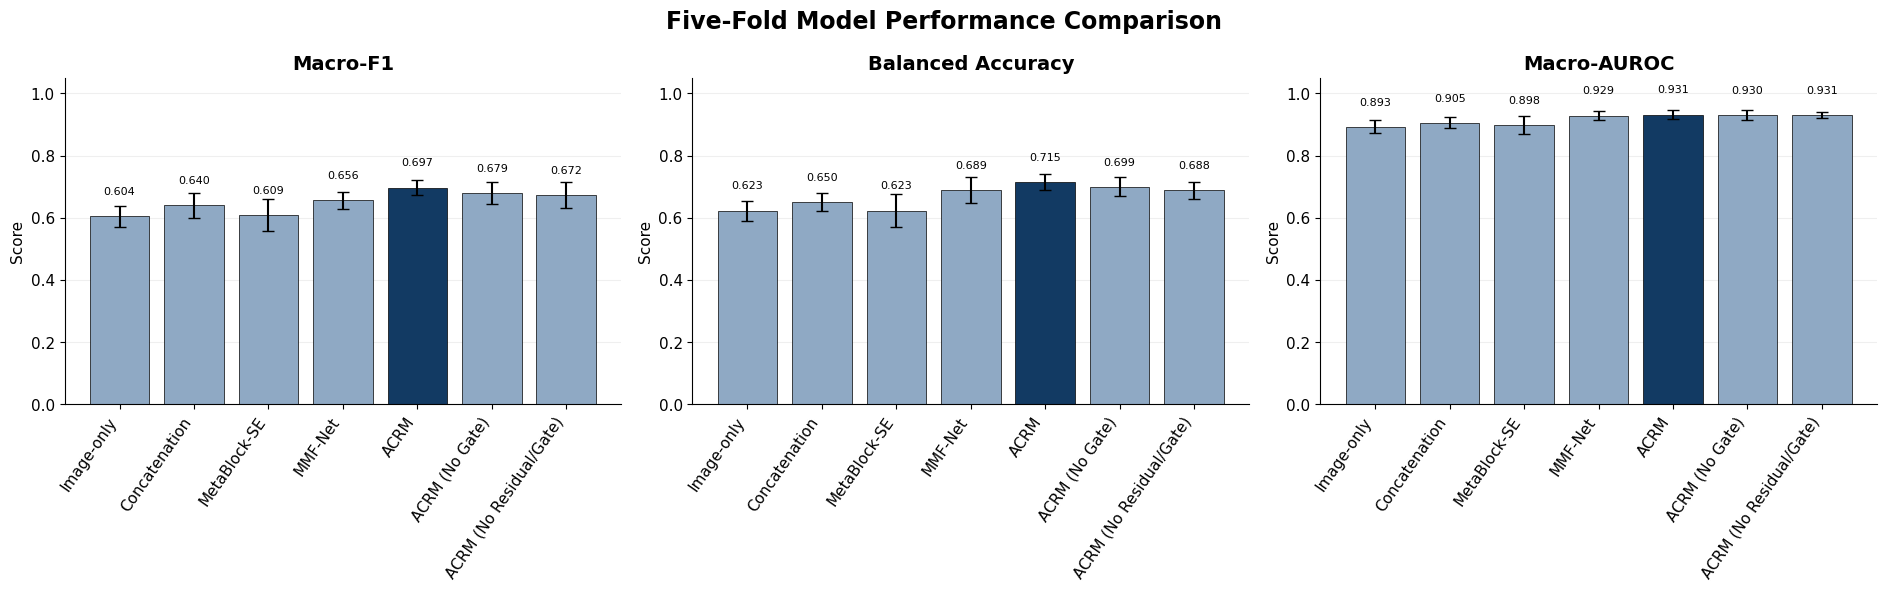

Figure saved: results/statistical_analysis/model_performance_comparison.png


In [20]:

import numpy as np
import matplotlib.pyplot as plt

model_order = [
    "image_only",
    "concat",
    "metablock_se",
    "mmfnet",
    "acrm",
    "acrm_no_gate",
    "acrm_no_residual_no_gate",
]

labels = [
    "Image-only",
    "Concatenation",
    "MetaBlock-SE",
    "MMF-Net",
    "ACRM",
    "ACRM (No Gate)",
    "ACRM (No Residual/Gate)",
]

metric_config = [
    ("macro_f1", "Macro-F1"),
    ("balanced_accuracy", "Balanced Accuracy"),
    ("macro_auroc", "Macro-AUROC"),
]

fig, axes = plt.subplots(1, 3, figsize=(19, 6))

for ax, (metric, title) in zip(axes, metric_config):
    means = [
        results[model][metric].mean()
        for model in model_order
    ]

    stds = [
        results[model][metric].std(ddof=1)
        for model in model_order
    ]

    positions = np.arange(len(model_order))

    bars = ax.bar(
        positions,
        means,
        yerr=stds,
        capsize=4,
        color=[
          "#123A63" if model == "acrm" else "#8FA9C4"
          for model in model_order
        ],
        edgecolor="black",
        linewidth=0.5,
    )

    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_xticks(positions)
    ax.set_xticklabels(labels, rotation=55, ha="right")
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Score")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

    for bar, mean in zip(bars, means):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            mean + 0.07,
            f"{mean:.3f}",
            ha="center",
            fontsize=8,
        )

fig.suptitle(
    "Five-Fold Model Performance Comparison",
    fontsize=17,
    fontweight="bold",
)

plt.tight_layout()

output_dir = REPO_DIR / "results" / "statistical_analysis"
output_dir.mkdir(parents=True, exist_ok=True)

figure_path = output_dir / "model_performance_comparison.png"

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(f"Figure saved: {figure_path.relative_to(REPO_DIR)}")



### Save Model Comparison Figure

The final model performance comparison figure is saved to the repository alongside the statistical analysis results for reproducibility and use in the final report.



### 14.3. Computational Complexity and Model Parameter Analysis

#### Objective

This analysis compares the architectural complexity of the seven evaluated model configurations using the same model implementations as the training experiments.

All architectures use the shared EfficientNet-B0 visual backbone, allowing differences in parameter counts to be attributed primarily to their metadata encoders, fusion mechanisms, and classification heads.

#### Model Input Configuration

The computational analysis uses the metadata representations defined by the training pipeline:

- **Image-only EfficientNet-B0:** No metadata input.
- **Feature concatenation:** Fold-preprocessed tabular metadata.
- **Adapted MetaBlock-SE:** A 768-dimensional sentence embedding.
- **Adapted MMF-Net:** Fold-preprocessed tabular metadata.
- **ACRM and its ablations:** Fold-preprocessed tabular metadata.

The eight selected clinical fields are transformed through training-fitted standardisation and one-hot encoding. The resulting encoded input dimensionality, rather than the number of original clinical fields, determines the metadata input size of the tabular models.

#### Parameter Measurements

For each architecture, the analysis reports:

1. **Total parameters:** All parameters registered in the model.
2. **Trainable parameters:** Parameters with `requires_grad=True`.
3. **Forward-used parameters:** Registered parameters expected to participate in the configured forward pass.
4. **Parameters (millions):** Total registered parameters expressed in millions.

#### ACRM Ablation Considerations

The ACRM ablation variants retain the gate projection module in their registered architecture, even when adaptive gating is disabled.

The analysis therefore distinguishes total registered parameters from forward-used parameters by excluding the unused gate-head parameters in the ungated configurations.

This distinction prevents registered model size from being confused with the operations executed during inference.

#### Interpretation and Limitations

Parameter counts quantify model size but do not directly measure inference time, floating-point operations, or GPU memory consumption.

Forward-used parameter counts are derived from the model configuration rather than dynamic execution tracing.

Inference latency and peak GPU memory allocation are evaluated separately in Section 14.4.

The analysis instantiates the model architectures without training or modifying previously saved classification results.

#### Output

The parameter comparison is saved to:

`results/statistical_analysis/model_parameter_comparison.csv`

The existing CSV is updated in place when the export cell is executed.


In [10]:

import pandas as pd

from pad_multimodal.models.factory import build_model

# Encoded metadata dimensionality from the training configuration.
# Confirm this value against the fitted preprocessing outputs
# for all five outer folds before running the analysis.
TABULAR_METADATA_DIM = 33
SENTENCE_EMBEDDING_DIM = 768

metadata_dims = {
    "image_only": None,
    "concat": TABULAR_METADATA_DIM,
    "metablock_se": SENTENCE_EMBEDDING_DIM,
    "mmfnet": TABULAR_METADATA_DIM,
    "acrm": TABULAR_METADATA_DIM,
    "acrm_no_gate": TABULAR_METADATA_DIM,
    "acrm_no_residual_no_gate": TABULAR_METADATA_DIM,
}

rows = []

for name, metadata_dim in metadata_dims.items():

    model = build_model(
        name,
        metadata_dim=metadata_dim,
    )

    total = sum(
        parameter.numel()
        for parameter in model.parameters()
    )

    trainable = sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )

    unused = 0

    if name in (
        "acrm_no_gate",
        "acrm_no_residual_no_gate",
    ):
        unused = sum(
            parameter.numel()
            for parameter in model.gate_head.parameters()
        )

    rows.append({
        "Model": name,
        "Metadata Input Dim": (
            metadata_dim if metadata_dim is not None else 0
        ),
        "Total Parameters": total,
        "Trainable Parameters": trainable,
        "Forward-Used Parameters": total - unused,
        "Parameters (M)": round(total / 1e6, 3),
    })

    del model

complexity_table = pd.DataFrame(rows)

display(complexity_table)


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 129MB/s]


,Model,Metadata Input Dim,Total Parameters,Trainable Parameters,Forward-Used Parameters,Parameters (M)
0,image_only,0,4015234,4015234,4015234,4.015
1,concat,33,4036866,4036866,4036866,4.037
2,metablock_se,768,4064578,4064578,4064578,4.065
3,mmfnet,33,4491266,4491266,4491266,4.491
4,acrm,33,4531458,4531458,4531458,4.531
5,acrm_no_gate,33,4531458,4531458,4366338,4.531
6,acrm_no_residual_no_gate,33,4531458,4531458,4366338,4.531



### Export Model Parameter Analysis

The model parameter counts are exported to a CSV file for reproducibility. The analysis distinguishes registered trainable parameters from parameters actively used in the forward computation, particularly for the ACRM ablation configurations.


In [11]:

from pathlib import Path

output_dir = REPO_DIR / "results" / "statistical_analysis"
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "model_parameter_comparison.csv"

complexity_table.to_csv(output_path, index=False)

print("Parameter analysis saved successfully.")
print(output_path.relative_to(REPO_DIR))


Parameter analysis saved successfully.
results/statistical_analysis/model_parameter_comparison.csv



### 14.4. Inference Latency and GPU Memory Benchmarking

#### Objective

Evaluate the computational efficiency of the seven model architectures under consistent inference conditions. This analysis complements the parameter-count comparison by measuring inference latency, timing variability, and GPU memory requirements.

#### Benchmark Configuration

The inference benchmark uses the following settings:

- **Hardware:** NVIDIA Tesla T4 GPU, when available.
- **Input resolution:** 224 × 224 RGB images.
- **Batch size:** 32 images.
- **Numerical precision:** FP32.
- **Warm-up:** 10 forward passes per model.
- **Timing repetitions:** 10 per model.
- **Forward passes per repetition:** 30.
- **Execution mode:** Evaluation mode with gradient computation disabled.
- **Input data:** Synthetic image and metadata tensors matching the model input dimensions.

The tabular models use the 33-dimensional encoded metadata configuration specified in Section 14.3, subject to verification against the saved training preprocessing. MetaBlock-SE uses its 768-dimensional embedding input.

CUDA synchronisation is applied around timing measurements to account for asynchronous GPU execution.

#### Performance Measurements

The benchmark reports:

1. **Mean batch latency (ms):** Average inference time per batch across timing repetitions.
2. **Standard deviation (ms):** Sample standard deviation of batch latency.
3. **Mean latency per image (ms):** Mean batch latency divided by batch size.
4. **Peak allocated GPU memory (MiB):** Maximum PyTorch GPU memory allocation during the benchmark.

#### Interpretation and Limitations

The benchmark measures model-forward execution rather than complete clinical inference. It excludes image loading, preprocessing, metadata preparation, and data-transfer overhead.

Models are instantiated without loading trained checkpoints. Therefore, the measurements describe architectural inference costs rather than predictive performance.

Timing repetitions are conducted within the same execution environment and do not represent independent hardware trials. Peak allocated GPU memory reflects PyTorch-managed allocations rather than total GPU memory consumption.

If CUDA is unavailable, latency is measured on the CPU and GPU memory is reported as unavailable.

#### Reproducibility

All architectures use the same image resolution, batch size, numerical precision, and timing protocol.

The computational environment and software versions are documented separately.

No model retraining is performed, and previously saved classification results remain unchanged.


In [12]:

import time
import numpy as np
import pandas as pd
import torch

from pad_multimodal.models.factory import build_model

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

batch_size = 32
warmup_runs = 10
repetitions = 10
passes_per_repetition = 30

# Reuse the model input dimensions established.
assert metadata_dims["acrm"] == 33
assert metadata_dims["metablock_se"] == 768

benchmark_rows = []

for name, metadata_dim in metadata_dims.items():

    model = build_model(
        name,
        metadata_dim=metadata_dim,
    ).to(device).eval()

    images = torch.randn(
        batch_size, 3, 224, 224,
        device=device,
    )

    metadata = (
        torch.randn(
            batch_size,
            metadata_dim,
            device=device,
        )
        if metadata_dim is not None
        else None
    )

    latencies = []

    with torch.inference_mode():

        for _ in range(warmup_runs):
            model(images, metadata)

        if device.type == "cuda":
            torch.cuda.synchronize()
            torch.cuda.reset_peak_memory_stats()

        for _ in range(repetitions):

            if device.type == "cuda":
                torch.cuda.synchronize()

            start = time.perf_counter()

            for _ in range(passes_per_repetition):
                model(images, metadata)

            if device.type == "cuda":
                torch.cuda.synchronize()

            elapsed = time.perf_counter() - start

            latencies.append(
                elapsed * 1000 / passes_per_repetition
            )

        peak_memory = (
            torch.cuda.max_memory_allocated() / (1024 ** 2)
            if device.type == "cuda"
            else np.nan
        )

    benchmark_rows.append({
        "Model": name,
        "Mean Batch Latency (ms)": round(
            np.mean(latencies), 3
        ),
        "SD Batch Latency (ms)": round(
            np.std(latencies, ddof=1), 3
        ),
        "Mean Latency per Image (ms)": round(
            np.mean(latencies) / batch_size, 4
        ),
        "Peak GPU Memory (MiB)": round(
            peak_memory, 2
        ),
    })

    print(
        f"{name}: "
        f"{np.mean(latencies):.3f} ± "
        f"{np.std(latencies, ddof=1):.3f} ms/batch"
    )

    del model, images, metadata

    if device.type == "cuda":
        torch.cuda.empty_cache()

benchmark_table = pd.DataFrame(benchmark_rows)

display(benchmark_table)


image_only: 33.040 ± 0.108 ms/batch
concat: 33.314 ± 0.094 ms/batch
metablock_se: 33.780 ± 0.458 ms/batch
mmfnet: 34.205 ± 0.113 ms/batch
acrm: 34.306 ± 0.116 ms/batch
acrm_no_gate: 34.689 ± 0.149 ms/batch
acrm_no_residual_no_gate: 35.073 ± 0.147 ms/batch


,Model,Mean Batch Latency (ms),SD Batch Latency (ms),Mean Latency per Image (ms),Peak GPU Memory (MiB)
0,image_only,33.040,0.108,1.0325,363.55
1,concat,33.314,0.094,1.0410,363.64
2,metablock_se,33.780,0.458,1.0556,363.84
3,mmfnet,34.205,0.113,1.0689,365.37
4,acrm,34.306,0.116,1.0721,365.53
5,acrm_no_gate,34.689,0.149,1.0840,365.53
6,acrm_no_residual_no_gate,35.073,0.147,1.0960,365.53



#### 14.4.1. ACRM Inference Timing Verification

The initial timing measurements showed comparatively high variability for the full ACRM architecture. A focused verification was therefore conducted to assess the stability of its inference latency.

The verification uses the same benchmark configuration, with 10 timing repetitions and 30 forward passes per repetition.

Individual repetition times are reported alongside the mean and sample standard deviation to assess measurement consistency.

The resulting measurements are used to verify the ACRM latency estimate before finalising the computational comparison.


In [13]:

import time
import numpy as np
import pandas as pd
import torch

acrm_metadata_dim = metadata_dims["acrm"]

model = build_model(
    "acrm",
    metadata_dim=acrm_metadata_dim,
).to(device).eval()

images = torch.randn(
    batch_size, 3, 224, 224,
    device=device,
)

metadata = torch.randn(
    batch_size, acrm_metadata_dim,
    device=device,
)

acrm_latencies = []

with torch.inference_mode():

    for _ in range(warmup_runs):
        model(images, metadata)

    if device.type == "cuda":
        torch.cuda.synchronize()

    for repetition in range(repetitions):

        if device.type == "cuda":
            torch.cuda.synchronize()

        start = time.perf_counter()

        for _ in range(passes_per_repetition):
            model(images, metadata)

        if device.type == "cuda":
            torch.cuda.synchronize()

        latency = (
            (time.perf_counter() - start)
            * 1000 / passes_per_repetition
        )

        acrm_latencies.append(latency)

acrm_repetitions = pd.DataFrame({
    "Repetition": range(1, repetitions + 1),
    "Batch Latency (ms)": np.round(acrm_latencies, 3),
})

display(acrm_repetitions)

print(
    f"Mean ± SD: {np.mean(acrm_latencies):.3f} ± "
    f"{np.std(acrm_latencies, ddof=1):.3f} ms/batch"
)

del model, images, metadata

if device.type == "cuda":
    torch.cuda.empty_cache()


,Repetition,Batch Latency (ms)
0,1,35.303
1,2,35.758
2,3,35.433
3,4,35.555
4,5,35.627
5,6,35.669
6,7,35.693
7,8,35.719
8,9,35.808
9,10,35.873


Mean ± SD: 35.644 ± 0.173 ms/batch



#### 14.4.2. Final Inference Benchmark Results

The primary inference benchmark evaluated all seven architectures using the same experimental configuration, including a batch size of 32, FP32 precision, 10 warm-up passes, and 10 timing repetitions of 30 forward passes each.

ACRM achieved a mean batch latency of **34.306 ± 0.116 ms** in the primary benchmark. A separate focused verification produced **35.644 ± 0.173 ms**, approximately 3.9% higher.

The difference illustrates variability between benchmark runs. The focused verification is reported separately rather than substituted into the primary comparison.

The final comparison table retains the measurements obtained from the primary seven-model benchmark to ensure consistent reporting across architectures.

All measurements describe model-forward inference with synthetic inputs, rather than end-to-end clinical prediction.


In [14]:

# Preserve the primary seven-model benchmark measurements.
# The focused ACRM verification is reported separately in Section 14.4.2.

benchmark_table["Benchmark Source"] = "Primary seven-model benchmark"

display(benchmark_table)

print(
    "\nACRM focused verification (reported separately): "
    f"{np.mean(acrm_latencies):.3f} ± "
    f"{np.std(acrm_latencies, ddof=1):.3f} ms/batch"
)


,Model,Mean Batch Latency (ms),SD Batch Latency (ms),Mean Latency per Image (ms),Peak GPU Memory (MiB),Benchmark Source
0,image_only,33.040,0.108,1.0325,363.55,Primary seven-model benchmark
1,concat,33.314,0.094,1.0410,363.64,Primary seven-model benchmark
2,metablock_se,33.780,0.458,1.0556,363.84,Primary seven-model benchmark
3,mmfnet,34.205,0.113,1.0689,365.37,Primary seven-model benchmark
4,acrm,34.306,0.116,1.0721,365.53,Primary seven-model benchmark
5,acrm_no_gate,34.689,0.149,1.0840,365.53,Primary seven-model benchmark
6,acrm_no_residual_no_gate,35.073,0.147,1.0960,365.53,Primary seven-model benchmark



ACRM focused verification (reported separately): 35.644 ± 0.173 ms/batch



### 14.5. Computational Environment

This section documents the computational environment used for inference benchmarking, including the Python, PyTorch, Torchvision, and CUDA versions, GPU hardware, and operating system.

The following cell also records the benchmark configuration, including the number of timing repetitions and numerical precision.

These details support reproducibility and provide context for interpreting differences in inference latency and GPU memory consumption across model architectures.

The cell records environment information only; it does not perform model training or modify experimental results.


In [15]:

import sys
import platform
import torch
import torchvision
import pandas as pd

environment = {
    "Python version": sys.version.split()[0],
    "PyTorch version": torch.__version__,
    "Torchvision version": torchvision.__version__,
    "CUDA version": torch.version.cuda,
    "GPU": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else "CPU only"
    ),
    "Operating system": platform.platform(),
    "Image resolution": "224 × 224",
    "Batch size": 32,
    "Warm-up iterations": 10,
    "Planned timing repetitions": 10,
    "Timed passes per repetition": 30,
    "Precision": "FP32 (no mixed precision)",
}

environment_table = pd.DataFrame(
    environment.items(),
    columns=["Setting", "Value"],
)

display(environment_table)


,Setting,Value
0,Python version,3.13.16
1,PyTorch version,2.14.1+cu130
2,Torchvision version,0.29.1+cu130
3,CUDA version,13.0
4,GPU,Tesla T4
5,Operating system,Linux-6.6.159+-x86_64-with-glibc2.39
6,Image resolution,224 × 224
7,Batch size,32
8,Warm-up iterations,10
9,Planned timing repetitions,10



### 14.6. Export Computational Benchmark Results

The final inference benchmark and computational environment information are exported to CSV files for reproducibility and subsequent analysis.

The exported files are:

- **`inference_benchmark.csv`:** Contains mean batch latency, sample standard deviation, per-image latency, peak allocated GPU memory, and the measurement source for each of the seven architectures.
- **`benchmark_environment.csv`:** Records the software environment, GPU hardware, numerical precision, and benchmark configuration.

Both files are saved under `results/statistical_analysis/`.

These outputs support the subsequent accuracy–efficiency comparison without repeating model training or inference benchmarking.


In [16]:

from pathlib import Path

output_dir = REPO_DIR / "results" / "statistical_analysis"
output_dir.mkdir(parents=True, exist_ok=True)

benchmark_path = output_dir / "inference_benchmark.csv"
environment_path = output_dir / "benchmark_environment.csv"

benchmark_table.to_csv(benchmark_path, index=False)
environment_table.to_csv(environment_path, index=False)

print("Saved successfully:")
print(benchmark_path.relative_to(REPO_DIR))
print(environment_path.relative_to(REPO_DIR))


Saved successfully:
results/statistical_analysis/inference_benchmark.csv
results/statistical_analysis/benchmark_environment.csv


## 15. Theoretical Computational Complexity and Implementation Attribution

#### Shared Visual Backbone

All seven architectures use EfficientNet-B0 as their visual feature extractor, with images resized to 224 × 224 pixels. EfficientNet employs compound scaling to balance network depth, width, and input resolution, providing an efficient convolutional architecture for image classification (Tan & Le, 2019).

Using the same visual backbone establishes a consistent computational foundation for comparing the different multimodal fusion strategies. The backbone accounts for most of the computational workload, while the fusion mechanisms introduce additional operations and parameters.

#### Concatenation-Based Fusion

The concatenation model encodes clinical metadata and combines its representation with the extracted visual features before classification. This approach provides a straightforward form of multimodal fusion by integrating representations from different modalities into a shared feature vector (Baltrušaitis et al., 2019).

Its additional computational cost primarily arises from the metadata encoder and classification layer, depending on their implemented dimensions.

#### MetaBlock-SE

MetaBlock-SE incorporates clinical metadata through channel-wise feature modulation. This mechanism is related to squeeze-and-excitation networks, which adaptively recalibrate feature responses using learned transformations (Hu et al., 2018).

Its computational overhead includes metadata projection, channel-wise transformations, and feature recalibration. The precise cost depends on the implemented architecture and feature dimensions.

#### MMF-Net

MMF-Net employs attention-based multimodal feature fusion, introducing attention projections, attention operations, and feature transformations.

Attention mechanisms enable learned interactions between representations, with computational requirements determined by the number of tokens, embedding dimensions, and attention layers (Vaswani et al., 2017).

Conventional multi-token self-attention introduces a quadratic interaction term with respect to sequence length. However, the implemented MMF-Net operates on compact modality representations rather than full image-patch sequences. Its computational cost should therefore not be equated with full image-patch cross-attention.

#### Adaptive Clinical Residual Modulation (ACRM)

The proposed ACRM architecture integrates clinical metadata into visual representations through three principal operations:

1. **Metadata encoding:** Projects clinical features into a learned hidden representation.
2. **Residual modulation:** Generates metadata-conditioned scale and shift transformations to adjust visual features.
3. **Adaptive gating:** Learns to regulate the contribution of metadata-conditioned residual information.

The architecture uses learned projections and element-wise feature modulation, conceptually related to feature-wise linear modulation (Perez et al., 2018).

Unlike conventional attention-based fusion, ACRM does not construct a token-to-token attention matrix.

Let:

- $B$ denote batch size.
- $d_m$ denote metadata input dimension.
- $h$ denote metadata hidden dimension.
- $d_v$ denote visual feature dimension.

The metadata encoder has an approximate computational complexity of:

$$
O\left(B(d_mh+h^2)\right)
$$

The three linear modulation heads, corresponding to scale, shift, and gate, require approximately:

$$
O(3Bhd_v)
$$

The element-wise modulation and gating operations require:

$$
O(Bd_v)
$$

Therefore, the additional computational complexity of the full ACRM fusion mechanism is approximately:

$$
O\left(B(d_mh+h^2+3hd_v+d_v)\right)
$$

These expressions describe the metadata encoder, linear modulation heads, and element-wise operations. They exclude the shared EfficientNet-B0 backbone and final classification layer.

Because ACRM operates on compact feature representations rather than image-patch attention matrices, its modulation mechanism avoids the quadratic token-interaction term associated with conventional multi-token self-attention (Vaswani et al., 2017).

However, this theoretical distinction does not establish that ACRM has lower overall computational cost than the alternative architectures. Actual efficiency must be evaluated using the empirical parameter-count, inference-latency, and GPU-memory measurements.

#### Computational Implications of ACRM Ablations

Two ablation configurations are evaluated to investigate the contribution of individual ACRM components:

- **ACRM without gate:** Disables adaptive gating while retaining residual modulation.
- **ACRM without residual and gate:** Disables both adaptive gating and residual modulation.

These configurations retain registered architectural components that may not participate in their forward computations.

Consequently, the total number of registered parameters can differ from the number of parameters actively used during inference.

The parameter-count analysis therefore distinguishes total registered parameters, trainable parameters, and forward-used parameters.

The theoretical complexity expression presented above applies to the full ACRM fusion mechanism. The ablation variants have different effective forward computations because selected modulation operations are disabled.

Empirical inference benchmarking provides complementary evidence of their actual execution costs.

#### Implementation Attribution

The project uses Torchvision's pretrained EfficientNet-B0 architecture as the shared visual backbone, based on the architecture introduced by Tan and Le (2019).

The project-specific implementation includes:

- The ACRM metadata encoder.
- Metadata-conditioned residual modulation.
- Adaptive gating.
- Integration of visual and clinical representations for classification.
- ACRM ablation configurations.

These components constitute the custom ACRM implementation developed for this study rather than a direct reproduction of an existing published architecture.

The experimental pipeline also includes patient-grouped cross-validation, model evaluation, prediction aggregation, statistical comparisons, and computational benchmarking.

Pretrained architectures and library-provided operations are distinguished from the custom research contribution to clarify the scope of implementation.

#### Interpretation and Limitations

Theoretical computational complexity, parameter counts, inference latency, and peak allocated GPU memory provide complementary measures of computational efficiency.

Parameter counts describe model size, while theoretical complexity characterises how computational requirements scale with input and feature dimensions.

Measured inference latency and GPU memory allocation additionally depend on hardware, numerical precision, software implementation, and execution conditions.

Peak allocated GPU memory is measured using PyTorch's CUDA memory statistics and does not represent total device memory consumption (PyTorch Contributors, n.d.).

The empirical measurements were obtained using an NVIDIA Tesla T4 GPU, FP32 precision, a batch size of 32, and synthetic inputs.

Accordingly, these measurements characterise computational behaviour under the specified experimental conditions rather than hardware-independent performance or complete clinical deployment costs.



## 16. Accuracy–Efficiency Trade-off Analysis

### 16.1. Comparative Evaluation

#### Objective

Evaluate whether improvements in classification performance are accompanied by increased computational requirements across the seven model architectures.

#### Evaluation Measures

The analysis combines:

- **Predictive performance:** Mean Macro-F1 across five patient-grouped cross-validation folds.
- **Model complexity:** Total registered parameters.
- **Inference latency:** Mean batch execution time and its standard deviation.
- **GPU memory:** Peak PyTorch-allocated memory during inference.

#### Comparative Analysis

The following cell combines the previously obtained classification and computational measurements into a single comparison table.

This enables assessment of the trade-off between predictive performance and computational efficiency, particularly whether the additional complexity introduced by ACRM is justified by its classification improvements.

The analysis uses existing experimental results and does not perform additional model training or inference benchmarking.


In [18]:

import pandas as pd

model_order = [
    "image_only",
    "concat",
    "metablock_se",
    "mmfnet",
    "acrm",
    "acrm_no_gate",
    "acrm_no_residual_no_gate",
]

accuracy_rows = []

for model in model_order:
    path = REPO_DIR / "results" / model / "fold_metrics.csv"

    if not path.is_file():
        raise FileNotFoundError(f"Missing results: {path}")

    df = pd.read_csv(path)

    if len(df) != 5:
        raise ValueError(
            f"{model}: expected 5 folds, found {len(df)}"
        )

    if "macro_f1" not in df.columns:
        raise KeyError(
            f"{model}: macro_f1 column missing from {path}"
        )

    accuracy_rows.append({
        "Model": model,
        "Mean Macro-F1": df["macro_f1"].mean(),
    })

accuracy_table = pd.DataFrame(accuracy_rows)

# Confirm that all three tables contain the same models.
expected = set(model_order)

assert set(accuracy_table["Model"]) == expected
assert set(complexity_table["Model"]) == expected
assert set(benchmark_table["Model"]) == expected

efficiency_table = (
    accuracy_table
    .merge(
        complexity_table[["Model", "Total Parameters"]],
        on="Model",
        validate="one_to_one",
    )
    .merge(
        benchmark_table[
            [
                "Model",
                "Mean Batch Latency (ms)",
                "SD Batch Latency (ms)",
                "Peak GPU Memory (MiB)",
            ]
        ],
        on="Model",
        validate="one_to_one",
    )
)

efficiency_table["Parameters (M)"] = (
    efficiency_table["Total Parameters"] / 1_000_000
)

efficiency_table = efficiency_table[
    [
        "Model",
        "Mean Macro-F1",
        "Parameters (M)",
        "Mean Batch Latency (ms)",
        "SD Batch Latency (ms)",
        "Peak GPU Memory (MiB)",
    ]
]

assert len(efficiency_table) == 7
assert not efficiency_table.isna().any().any()

display(efficiency_table.round(4))


,Model,Mean Macro-F1,Parameters (M),Mean Batch Latency (ms),SD Batch Latency (ms),Peak GPU Memory (MiB)
0,image_only,0.6042,4.0152,33.040,0.108,363.55
1,concat,0.6396,4.0369,33.314,0.094,363.64
2,metablock_se,0.6088,4.0646,33.780,0.458,363.84
3,mmfnet,0.6564,4.4913,34.205,0.113,365.37
4,acrm,0.6970,4.5315,34.306,0.116,365.53
5,acrm_no_gate,0.6791,4.5315,34.689,0.149,365.53
6,acrm_no_residual_no_gate,0.6722,4.5315,35.073,0.147,365.53



### 16.2. Accuracy–Efficiency Visualisation

This section visualises the relationship between predictive performance and inference cost across the seven model architectures.

The figure presents two aligned comparisons:

1. **Classification performance:** Mean Macro-F1 obtained from five-fold patient-grouped cross-validation.
2. **Inference efficiency:** Mean batch inference latency, with error bars representing the sample standard deviation across timing repetitions.

Full ACRM is highlighted to distinguish the proposed architecture from the baseline models and ablation configurations.

Higher Macro-F1 indicates better predictive performance, while lower inference latency indicates greater computational efficiency under the evaluated conditions.

The figure supports a descriptive comparison of accuracy and computational cost. Small latency differences should be interpreted cautiously, particularly because the verified ACRM measurement was obtained in a separate timing run.


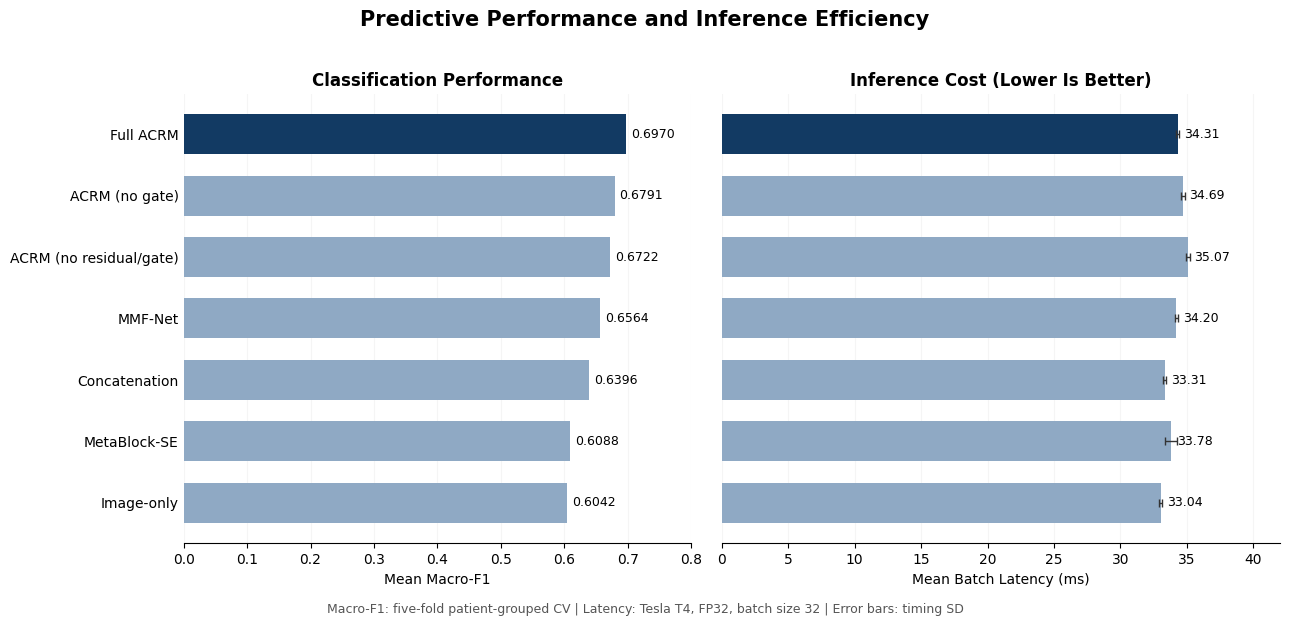

Saved: results/statistical_analysis/accuracy_efficiency_tradeoff.png


In [19]:

import numpy as np
import matplotlib.pyplot as plt

plot_data = efficiency_table.copy()

labels = {
    "image_only": "Image-only",
    "concat": "Concatenation",
    "metablock_se": "MetaBlock-SE",
    "mmfnet": "MMF-Net",
    "acrm": "Full ACRM",
    "acrm_no_gate": "ACRM (no gate)",
    "acrm_no_residual_no_gate": "ACRM (no residual/gate)",
}

plot_data["Label"] = plot_data["Model"].map(labels)
plot_data = plot_data.sort_values("Mean Macro-F1")

colors = [
    "#123A63" if model == "acrm" else "#8FA9C4"
    for model in plot_data["Model"]
]

y = np.arange(len(plot_data))

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5.8),
    sharey=True,
    gridspec_kw={"width_ratios": [1, 1.1]},
)

axes[0].barh(
    y,
    plot_data["Mean Macro-F1"],
    color=colors,
    height=0.65,
)

axes[0].set_yticks(y)
axes[0].set_yticklabels(plot_data["Label"])
axes[0].set_xlim(0, 0.8)
axes[0].set_xlabel("Mean Macro-F1")
axes[0].set_title("Classification Performance", fontweight="bold")

for i, value in enumerate(plot_data["Mean Macro-F1"]):
    axes[0].text(
        value + 0.008, i,
        f"{value:.4f}",
        va="center",
        fontsize=9,
    )

axes[1].barh(
    y,
    plot_data["Mean Batch Latency (ms)"],
    color=colors,
    height=0.65,
)

axes[1].errorbar(
    plot_data["Mean Batch Latency (ms)"],
    y,
    xerr=plot_data["SD Batch Latency (ms)"],
    fmt="none",
    ecolor="#333333",
    capsize=3,
    linewidth=1,
)

axes[1].set_xlim(0, 42)
axes[1].set_xlabel("Mean Batch Latency (ms)")
axes[1].set_title("Inference Cost (Lower Is Better)", fontweight="bold")

for i, value in enumerate(plot_data["Mean Batch Latency (ms)"]):
    axes[1].text(
        value + 0.5, i,
        f"{value:.2f}",
        va="center",
        fontsize=9,
    )

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="x", alpha=0.12)
    ax.set_axisbelow(True)

fig.suptitle(
    "Predictive Performance and Inference Efficiency",
    fontsize=15,
    fontweight="bold",
    y=1.02,
)

fig.text(
    0.5, -0.02,
    "Macro-F1: five-fold patient-grouped CV | "
    "Latency: Tesla T4, FP32, batch size 32 | "
    "Error bars: timing SD",
    ha="center",
    fontsize=9,
    color="#555555",
)

plt.tight_layout()

output_path = (
    REPO_DIR
    / "results"
    / "statistical_analysis"
    / "accuracy_efficiency_tradeoff.png"
)

fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", output_path.relative_to(REPO_DIR))


In [20]:

from pathlib import Path

output_dir = REPO_DIR / "results" / "statistical_analysis"
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "accuracy_efficiency_comparison.csv"

efficiency_table.to_csv(output_path, index=False)

print("Saved successfully:")
print(output_path.relative_to(REPO_DIR))


Saved successfully:
results/statistical_analysis/accuracy_efficiency_comparison.csv



### 16.3. Interpretation of Accuracy–Efficiency Results

The accuracy–efficiency comparison indicates that ACRM achieved the highest mean Macro-F1 (0.6970) among the seven evaluated configurations, compared with 0.6564 for MMF-Net, 0.6396 for feature concatenation, and 0.6042 for the image-only baseline.

Relative to image-only EfficientNet-B0, ACRM improved mean Macro-F1 by 9.28 percentage points, while increasing the total parameter count from 4.0152 million to 4.5315 million (approximately 12.86%). Mean batch inference latency increased from 33.040 ms to 34.306 ms (approximately 3.83%), while measured peak GPU memory allocation increased from 363.55 MiB to 365.53 MiB (approximately 0.54%).

Compared with MMF-Net, ACRM improved mean Macro-F1 by 4.06 percentage points, with approximately 0.90% more parameters and 0.30% higher measured batch latency. These results suggest that metadata-guided residual modulation provides a favourable accuracy–efficiency trade-off within the evaluated experimental setting.

The ACRM ablations achieved lower mean Macro-F1 scores of 0.6791 without gating and 0.6722 without gating or residual preservation. Although all three variants retained the same registered parameter count, the ungated configurations excluded the gate-head parameters from their forward computations.

These findings should be interpreted within the limitations of the computational benchmark. Latency and memory measurements were obtained using synthetic inputs and untrained model instances on the available hardware. They therefore characterise architectural computational requirements rather than end-to-end clinical deployment performance. Small differences in measured inference latency should not be interpreted as statistically established efficiency advantages.



### 16.4. Computational Analysis: Final Verification

This section verifies the saved computational analysis outputs, including model parameter counts, inference latency, GPU memory allocation, computational environment information, and accuracy–efficiency comparisons.

The verification checks file availability, table dimensions, missing values, and model coverage to support the completeness and reproducibility of the reported results.

This step reads existing CSV files without retraining models or modifying experimental results.


In [21]:

import subprocess

subprocess.run(
    ["git", "-C", str(REPO_DIR), "status", "--short"],
    check=True
)


CompletedProcess(args=['git', '-C', '/content/PAD_UFES_Capstone', 'status', '--short'], returncode=0)

In [ ]:

from google.colab import _message
from pathlib import Path
import json

# Retrieve the currently open notebook, including recent edits.
notebook = _message.blocking_request(
    "get_ipynb",
    timeout_sec=120,
)["ipynb"]

# Save a clean copy in the cloned GitHub repository.
notebook_dir = REPO_DIR / "notebooks"
notebook_dir.mkdir(parents=True, exist_ok=True)

notebook_path = notebook_dir / "PAD_UFES_Capstone_Experiments.ipynb"

with open(notebook_path, "w", encoding="utf-8") as f:
    json.dump(notebook, f, ensure_ascii=False, indent=1)

print("Notebook saved:", notebook_path.relative_to(REPO_DIR))


In [22]:

import subprocess
from pathlib import Path

NOTEBOOK_PATH = "notebooks/PAD_UFES_Capstone_Experiments.ipynb"  # Adjust if needed

files_to_commit = [
    NOTEBOOK_PATH,
    "results/statistical_analysis/model_parameter_comparison.csv",
    "results/statistical_analysis/inference_benchmark.csv",
    "results/statistical_analysis/benchmark_environment.csv",
    "results/statistical_analysis/accuracy_efficiency_comparison.csv",
]

for relative_path in files_to_commit:
    if not (REPO_DIR / relative_path).is_file():
        raise FileNotFoundError(
            f"Missing repository file: {relative_path}"
        )

subprocess.run(
    ["git", "-C", str(REPO_DIR), "add", "--", *files_to_commit],
    check=True
)

subprocess.run(
    [
        "git", "-C", str(REPO_DIR),
        "diff", "--cached", "--stat"
    ],
    check=True
)

subprocess.run(
    [
        "git", "-C", str(REPO_DIR),
        "commit", "-m",
        "Finalise experimental notebook and computational benchmarks"
    ],
    check=True
)


FileNotFoundError: Missing repository file: notebooks/PAD_UFES_Capstone_Experiments.ipynb

In [37]:

from pathlib import Path
import pandas as pd

results_dir = REPO_DIR / "results" / "statistical_analysis"

expected_files = [
    "model_parameter_comparison.csv",
    "inference_benchmark.csv",
    "benchmark_environment.csv",
    "accuracy_efficiency_comparison.csv",
]

for filename in expected_files:
    path = results_dir / filename

    if not path.exists():
        print(f"MISSING: {filename}")
        continue

    df = pd.read_csv(path)

    print(f"\n{filename}")
    print(f"  Rows: {len(df)}")
    print(f"  Columns: {len(df.columns)}")
    print(f"  Missing values: {df.isna().sum().sum()}")

    if "Model" in df.columns:
        print(f"  Models: {df['Model'].nunique()}")



model_parameter_comparison.csv
  Rows: 7
  Columns: 5
  Missing values: 0
  Models: 7

inference_benchmark.csv
  Rows: 7
  Columns: 6
  Missing values: 0
  Models: 7

benchmark_environment.csv
  Rows: 12
  Columns: 2
  Missing values: 0

accuracy_efficiency_comparison.csv
  Rows: 7
  Columns: 6
  Missing values: 0
  Models: 7

Git status:


CompletedProcess(args=['git', 'status', '--short'], returncode=0)


## References

Baltrušaitis, T., Ahuja, C., & Morency, L.-P. (2019). Multimodal machine learning: A survey and taxonomy. *IEEE Transactions on Pattern Analysis and Machine Intelligence, 41*(2), 423–443. https://doi.org/10.1109/TPAMI.2018.2798607

Hu, J., Shen, L., & Sun, G. (2018). Squeeze-and-excitation networks. *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition*, 7132–7141. https://doi.org/10.1109/CVPR.2018.00745

Pacheco, A. G. C., Lima, G. R., Salomão, A. S., Krohling, B., Biral, I. P., de Angelo, G. G., Alves, F. C. R., Jr., Esgario, J. G. M., Simora, A. C., Castro, P. B. C., Rodrigues, F. B., Frasson, P. H. L., Krohling, R. A., Knidel, H., Santos, M. C. S., do Espírito Santo, R. B., Macedo, T. L. S. G., Canuto, T. R. P., & de Barros, L. F. S. (2020). PAD-UFES-20: A skin lesion dataset composed of patient data and clinical images collected from smartphones. *Data in Brief, 32*, 106221. https://doi.org/10.1016/j.dib.2020.106221

Perez, E., Strub, F., de Vries, H., Dumoulin, V., & Courville, A. (2018). FiLM: Visual reasoning with a general conditioning layer. *Proceedings of the AAAI Conference on Artificial Intelligence, 32*(1), 3942–3951. https://doi.org/10.1609/aaai.v32i1.11671

PyTorch Contributors. (n.d.). *torch.cuda.memory.max_memory_allocated*. PyTorch documentation. https://docs.pytorch.org/docs/main/generated/torch.cuda.memory.max_memory_allocated.html

Tan, M., & Le, Q. V. (2019). EfficientNet: Rethinking model scaling for convolutional neural networks. *Proceedings of the 36th International Conference on Machine Learning, 97*, 6105–6114. https://proceedings.mlr.press/v97/tan19a.html

Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A. N., Kaiser, Ł., & Polosukhin, I. (2017). Attention is all you need. *Advances in Neural Information Processing Systems, 30*. https://mlanthology.org/neurips/2017/vaswani2017neurips-attention/
